# Neural Hydrology Explorer — exploration notebook

This notebook walks through the whole learning workflow on real data:

1. **Phase 1 – look at the data**: one basin's weather (dynamic inputs), its static attributes and the observed streamflow (target).
2. **Phase 2/3 – model results**: observed vs predicted hydrographs, NSE / KGE, LSTM vs Transformer.
3. A tiny **flood-threshold** demonstration.

Run `python scripts/download_data.py` first (and `python scripts/train.py && python scripts/evaluate.py && python scripts/compare.py`
for the model sections). Every number printed here comes from the files under `data/` and `outputs/`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from nhplay.data.camels import (DYNAMIC_INPUTS, STATIC_ATTRIBUTES, TARGET, load_basin, load_attributes,
                                load_discharge_cfs, basin_summary, read_basin_list)
from nhplay.evaluation import metrics as M
from nhplay.visualization import plots
from nhplay.paths import PREDICTION_DIR, METRIC_DIR

%matplotlib inline
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
basins = read_basin_list()
basins

['01022500', '02177000', '07057500', '08171300', '11532500', '13235000']

## Phase 1 · the six basins and their static attributes

One row per basin, constant in time. These are the model's **static inputs**.

In [2]:
attrs = load_attributes(basins)
attrs[["gauge_name", "area_gages2", "elev_mean", "slope_mean", "frac_forest", "aridity", "frac_snow", "p_mean", "soil_depth_pelletier"]].round(2)

,gauge_name,area_gages2,elev_mean,slope_mean,frac_forest,aridity,frac_snow,p_mean,soil_depth_pelletier
gauge_id,,,,,,,,,
01022500,"Narraguagus River at Cherryfield, Maine",573.60,92.68,17.79,0.92,0.59,0.25,3.61,17.41
02177000,"CHATTOOGA RIVER NEAR CLAYTON, GA",526.77,705.59,47.86,0.97,0.52,0.03,5.37,1.00
07057500,"North Fork River near Tecumseh, MO",1456.44,324.68,11.24,0.58,0.85,0.06,3.26,2.40
08171300,"Blanco Rv nr Kyle, TX",1067.47,379.23,13.98,0.06,1.83,0.00,2.56,1.25
11532500,SMITH R NR CRESCENT CITY CA,1577.96,725.07,112.11,1.00,0.42,0.05,5.58,0.94
13235000,SF PAYETTE RIVER AT LOWMAN ID,1163.23,2075.34,126.25,0.86,1.05,0.68,2.57,0.44


### Which columns are inputs and which is the target?

In [3]:
bd = load_basin("01022500")   # Narraguagus River at Cherryfield, Maine
bd.variable_table()

,role,variable,meaning
0,DYNAMIC input,prcp(mm/day),"Precipitation (rain + snow water equivalent), ..."
1,DYNAMIC input,tmax(C),"Daily maximum air temperature, deg C"
2,DYNAMIC input,tmin(C),"Daily minimum air temperature, deg C"
3,DYNAMIC input,srad(W/m2),Incoming shortwave solar radiation (drives eva...
4,DYNAMIC input,vp(Pa),Water vapour pressure (humidity)
5,"in file, not used",dayl(s),Day length in seconds (deterministic from lati...
6,"in file, not used",swe(mm),Snow water equivalent estimated by Daymet (a m...
7,STATIC attribute,area_gages2,"Basin (drainage) area, km^2"
8,STATIC attribute,elev_mean,"Mean elevation, m above sea level"
9,STATIC attribute,slope_mean,"Mean terrain slope, m/km"


### Dynamic inputs + target: the daily table for one basin

Each row is one day. The first five columns are **weather** (what the model sees); the last one is **observed streamflow** (what it must predict).

In [4]:
ts = bd.timeseries[list(DYNAMIC_INPUTS) + ["QObs(mm/d)"]]
print(ts.shape, "days x columns ;", ts.index.min().date(), "to", ts.index.max().date())
ts.loc["2010-09-28":"2010-10-08"].round(2)

(12784, 6) days x columns ; 1980-01-01 to 2014-12-31


,prcp(mm/day),tmax(C),tmin(C),srad(W/m2),vp(Pa),QObs(mm/d)
date,,,,,,
2010-09-28,4.14,18.22,10.93,172.76,1314.02,0.26
2010-09-29,3.91,22.28,15.33,160.72,1746.54,0.30
2010-09-30,0.00,22.44,13.13,274.52,1502.42,0.31
2010-10-01,8.86,20.87,14.50,153.01,1651.23,0.32
2010-10-02,26.42,19.10,9.67,214.70,1213.23,1.31
2010-10-03,0.00,16.43,2.60,357.48,734.09,1.54
2010-10-04,0.00,15.13,5.15,300.72,886.87,1.09
2010-10-05,0.00,16.62,6.52,298.41,966.75,0.82
2010-10-06,0.00,18.05,6.94,310.76,995.64,0.66


Read the table: 26.4 mm of rain fell on 2 Oct 2010. The river rose from 0.32 to 1.31 mm/day the same day, peaked at
1.54 mm/day on 3 Oct (one day *after* the rain) and then drained slowly over the following days. That shape — rising limb, peak,
recession — is the basic unit of a **hydrograph**.

### The unit conversion: from cubic feet per second at the gauge to mm/day over the basin

In [5]:
cfs = load_discharge_cfs("01022500")
area_m2 = bd.area_m2
demo = pd.DataFrame({"QObs(cfs)": cfs.loc["2010-10-01":"2010-10-04"]})
demo["QObs(mm/d) by hand"] = demo["QObs(cfs)"] * 0.0283168 * 86400 / area_m2 * 1000
demo["QObs(mm/d) NeuralHydrology"] = bd.timeseries.loc["2010-10-01":"2010-10-04", "QObs(mm/d)"]
print(f"basin area = {area_m2/1e6:.1f} km^2")
demo.round(3)

basin area = 587.7 km^2


,QObs(cfs),QObs(mm/d) by hand,QObs(mm/d) NeuralHydrology
date,,,
2010-10-01,77.0,0.321,0.321
2010-10-02,315.0,1.311,1.311
2010-10-03,371.0,1.545,1.545
2010-10-04,261.0,1.087,1.087


### Plots: rain, temperature and streamflow for one water year, then the full record

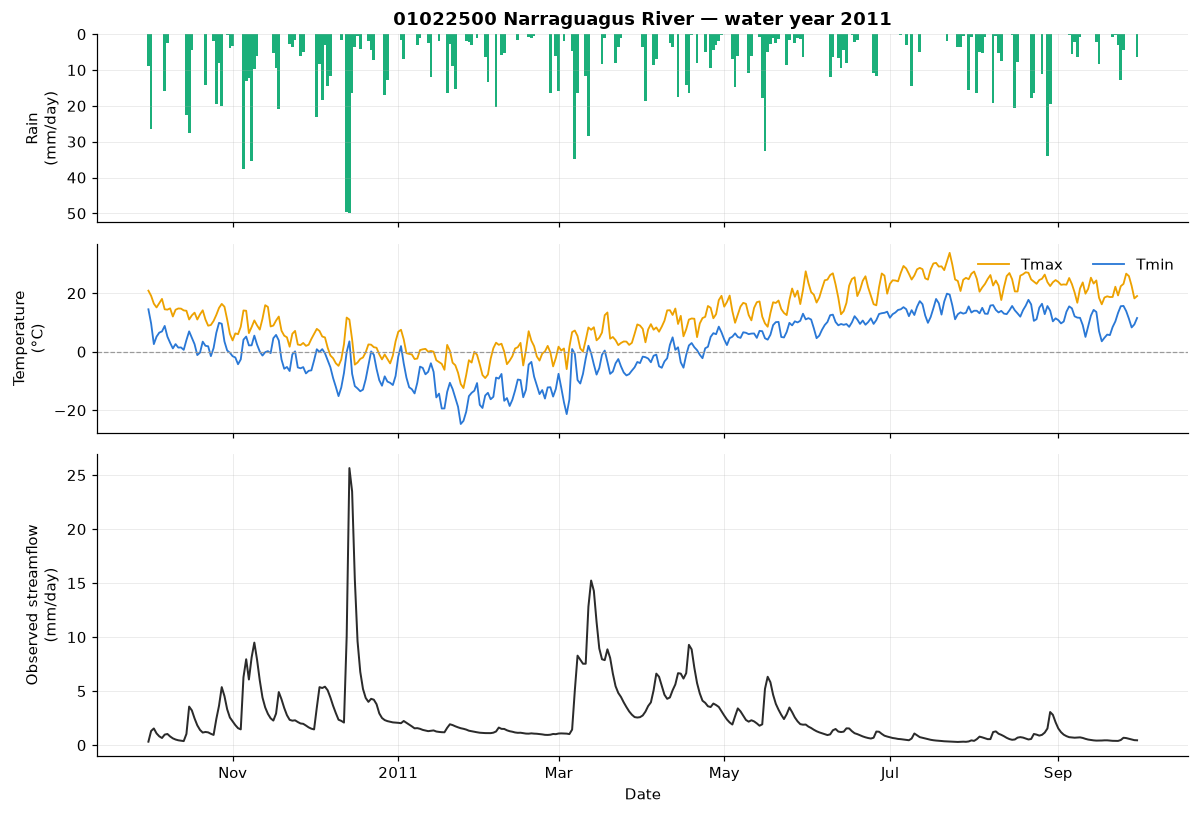

In [6]:
fig = plots.plot_forcing_and_flow(bd.timeseries, "01022500 Narraguagus River — water year 2011", start="2010-10-01", end="2011-09-30")
plt.show()

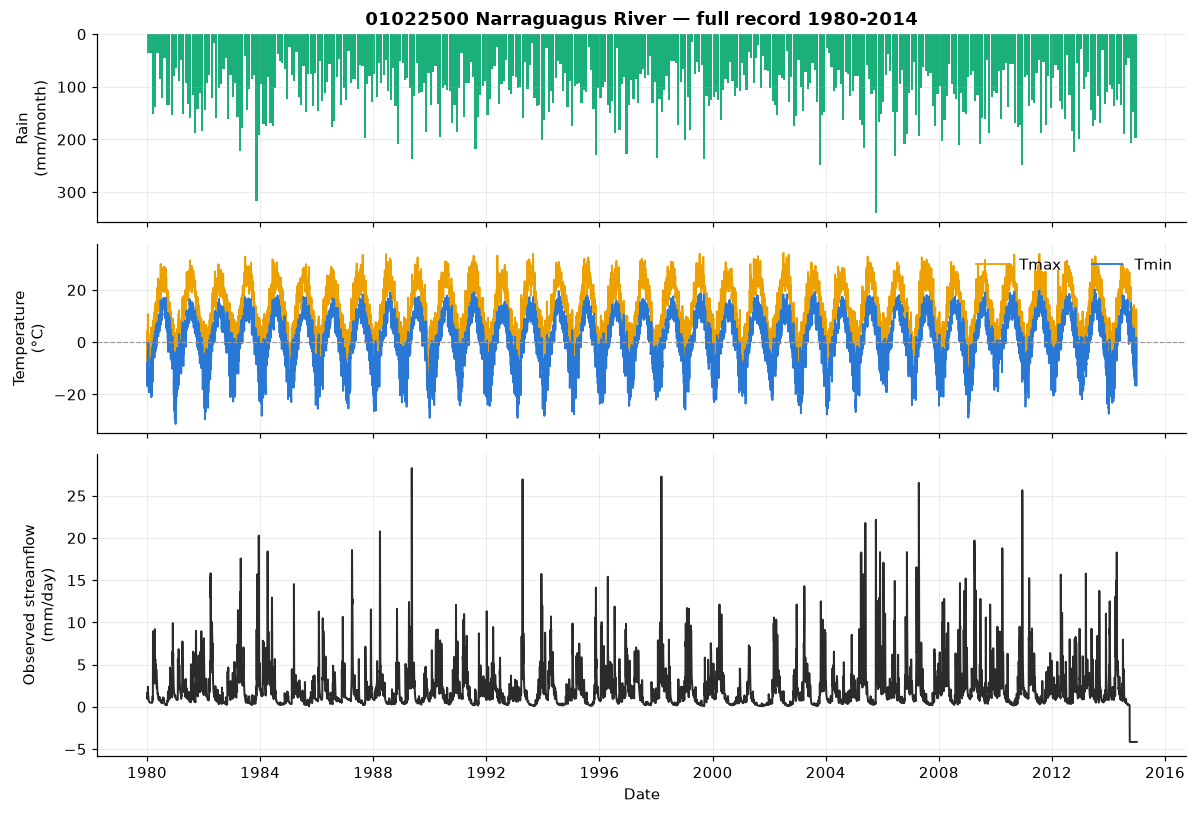

In [7]:
fig = plots.plot_forcing_and_flow(bd.timeseries, "01022500 Narraguagus River — full record 1980-2014")
plt.show()

### Water balance: how much of the rain leaves as river flow?

Because both are in mm/day we can compare them directly. The **runoff ratio** varies from 15 % (hot, dry Texas) to 97 % (wet, cool Pacific coast).

In [8]:
rows = []
for b in basins:
    d = load_basin(b)
    t = d.timeseries
    rows.append({"basin": b, "name": d.attributes["gauge_name"], "mean rain mm/day": t["prcp(mm/day)"].mean(),
                 "mean flow mm/day": t["QObs(mm/d)"].mean(), "runoff ratio": t["QObs(mm/d)"].mean() / t["prcp(mm/day)"].mean(),
                 "max flow mm/day": t["QObs(mm/d)"].max(), "date of max": t["QObs(mm/d)"].idxmax().date()})
pd.DataFrame(rows).round(2)

,basin,name,mean rain mm/day,mean flow mm/day,runoff ratio,max flow mm/day,date of max
0,01022500,"Narraguagus River at Cherryfield, Maine",3.62,2.07,0.57,28.27,1989-05-13
1,02177000,"CHATTOOGA RIVER NEAR CLAYTON, GA",5.29,2.77,0.52,84.46,2004-09-17
2,07057500,"North Fork River near Tecumseh, MO",3.19,1.28,0.40,75.97,1985-11-19
3,08171300,"Blanco Rv nr Kyle, TX",2.46,0.36,0.15,59.64,1998-10-17
4,11532500,SMITH R NR CRESCENT CITY CA,5.67,5.50,0.97,140.37,1998-11-21
5,13235000,SF PAYETTE RIVER AT LOWMAN ID,2.66,1.74,0.65,16.15,2010-06-05


### Why the past matters: the same rain on a dry vs a wet basin (Blanco River, Texas)

In [9]:
t = load_basin("08171300").timeseries
top = t["QObs(mm/d)"].nlargest(5)
pd.DataFrame({
    "flow mm/day": top,
    "rain that day": [t.loc[d, "prcp(mm/day)"] for d in top.index],
    "rain previous 3 days": [t.loc[d - pd.Timedelta(days=3): d - pd.Timedelta(days=1), "prcp(mm/day)"].sum() for d in top.index],
    "flow the day before": [t.loc[d - pd.Timedelta(days=1), "QObs(mm/d)"] for d in top.index],
}).round(1)

,flow mm/day,rain that day,rain previous 3 days,flow the day before
date,,,,
1998-10-17,59.6,152.1,0.0,0.1
2002-07-05,46.1,62.6,215.7,21.9
1997-06-22,45.0,125.4,19.4,1.7
1991-12-21,43.6,87.6,151.1,16.1
2001-11-15,42.7,56.3,0.0,0.2


### Snow: rain in December, river in June (South Fork Payette, Idaho)

In [10]:
t = load_basin("13235000").timeseries
t.loc["2010-10-01":"2011-09-30", ["prcp(mm/day)", "tmax(C)", "QObs(mm/d)"]].resample("MS").mean().round(2)

,prcp(mm/day),tmax(C),QObs(mm/d)
date,,,
2010-10-01,3.37,12.66,0.74
2010-11-01,4.32,1.99,0.72
2010-12-01,5.97,-0.46,0.71
2011-01-01,3.23,0.08,0.82
2011-02-01,2.30,0.23,0.66
2011-03-01,6.84,3.24,0.77
2011-04-01,4.74,5.59,1.54
2011-05-01,3.21,11.59,4.91
2011-06-01,1.48,16.08,7.99


## Phase 2/3 · model results (LSTM vs Transformer)

The cells below read `outputs/predictions/*.csv` written by `scripts/evaluate.py`. Both models were trained on the same six basins,
the same inputs and target, and the same chronological split (train 1980-1999, validation 1999-2004, **test 2004-2014**).

In [11]:
preds = {}
for m in ("lstm", "transformer"):
    f = PREDICTION_DIR / f"{m}_test.csv"
    if f.exists():
        preds[m] = pd.read_csv(f, dtype={"basin": str}, parse_dates=["date"])
print("models with predictions:", list(preds))
if not preds:
    print("Run: python scripts/train.py && python scripts/evaluate.py && python scripts/compare.py")

models with predictions: ['lstm', 'transformer']


In [12]:
if preds:
    rows = []
    for m, p in preds.items():
        for b, g in p.groupby("basin"):
            sc = M.scorecard(g["obs"].values, g["sim"].values).as_dict()
            rows.append({"basin": b, "model": m, **sc})
    table = pd.DataFrame(rows)
    display(table.pivot(index="basin", columns="model", values=["nse", "kge"]).round(3))
    display(table.groupby("model")[["nse", "kge", "r", "alpha", "beta", "fhv"]].median().round(3))

nse                kge            
model      lstm transformer   lstm transformer
basin                                         
01022500  0.837       0.357  0.827       0.513
02177000  0.843       0.510  0.848       0.644
07057500  0.732       0.392  0.648       0.504
08171300  0.659       0.340  0.289       0.650
11532500  0.754       0.593  0.671       0.638
13235000  0.891       0.643  0.789       0.706

,nse,kge,r,alpha,beta,fhv
model,,,,,,
lstm,0.796,0.730,0.903,0.843,1.011,-9.701
transformer,0.451,0.641,0.701,0.772,1.032,-21.230


### Hydrographs: observed vs predicted for one water year of the test period

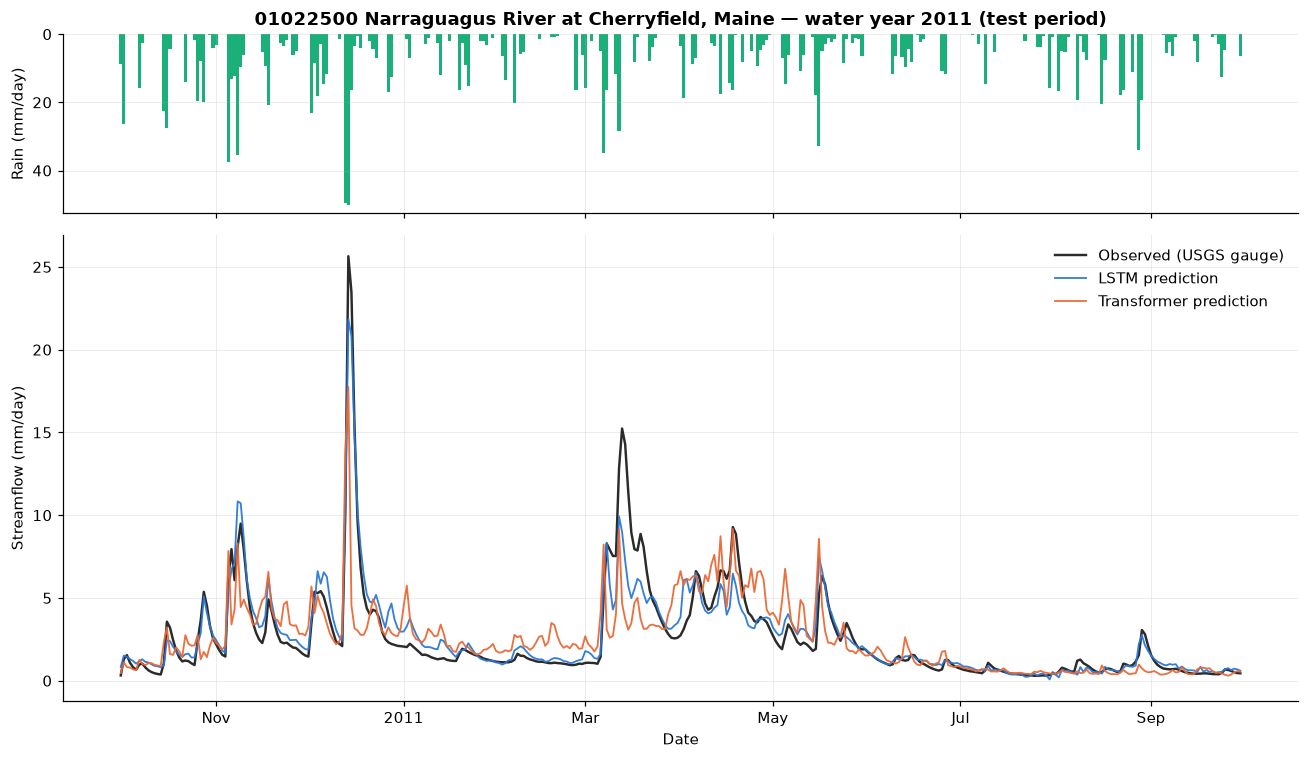

In [13]:
if preds:
    basin = "01022500"
    d = load_basin(basin)
    obs = preds[next(iter(preds))].query("basin == @basin").set_index("date")["obs"]
    sims = {m: p.query("basin == @basin").set_index("date")["sim"] for m, p in preds.items()}
    fig = plots.plot_hydrograph(obs, sims, f"{basin} {d.attributes['gauge_name']} — water year 2011 (test period)",
                                rain=d.timeseries["prcp(mm/day)"], start="2010-10-01", end="2011-09-30")
    plt.show()

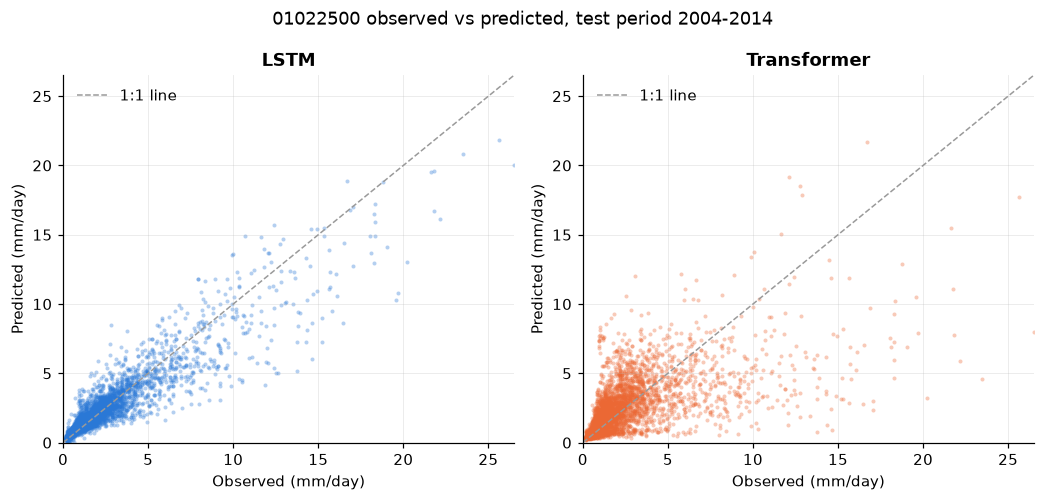

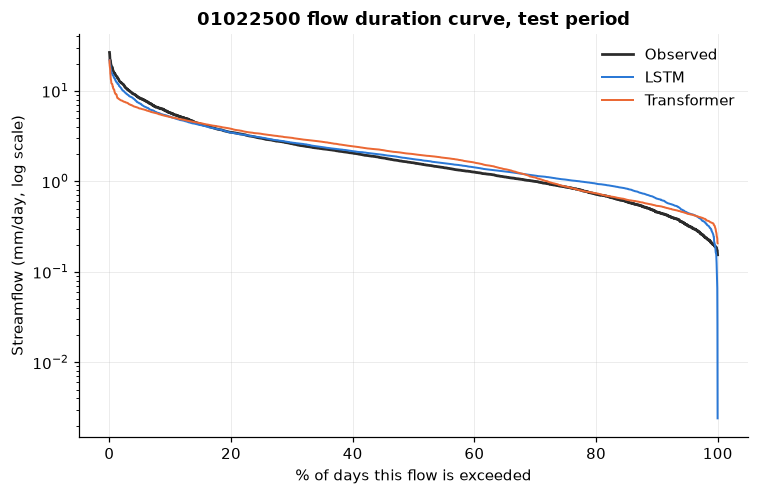

In [14]:
if preds:
    fig = plots.plot_scatter(obs, sims, f"{basin} observed vs predicted, test period 2004-2014"); plt.show()
    fig = plots.plot_flow_duration_curve(obs, sims, f"{basin} flow duration curve, test period"); plt.show()

### The biggest observed flood of the test period in each basin, and what each model said that day

In [15]:
if preds:
    rows = []
    for b in basins:
        d = load_basin(b)
        o = preds[next(iter(preds))].query("basin == @b").set_index("date")["obs"]
        day = o.idxmax()
        row = {"basin": b, "peak date": day.date(), "rain that day mm": d.timeseries.loc[day, "prcp(mm/day)"], "observed mm/day": o.max()}
        for m, p in preds.items():
            row[m + " mm/day"] = p.query("basin == @b").set_index("date").loc[day, "sim"]
        rows.append(row)
    display(pd.DataFrame(rows).round(1))

,basin,peak date,rain that day mm,observed mm/day,lstm mm/day,transformer mm/day
0,01022500,2007-04-18,16.7,26.5,20.0,8.0
1,02177000,2009-09-20,78.3,32.3,10.8,11.5
2,07057500,2011-04-26,64.4,68.2,30.9,14.8
3,08171300,2013-10-31,87.2,38.3,16.3,17.4
4,11532500,2008-12-28,90.3,118.4,36.2,34.2
5,13235000,2010-06-05,3.6,16.1,5.7,7.9


## A tiny flood-threshold demonstration (educational only)

Operational systems compare forecasts with return-period thresholds (e.g. the 2-year flood). We have no official flood stages for
these gauges, so we simply use the 99th percentile of each basin's observed daily flow and count exceedance days in the test period.

In [16]:
if preds:
    rows = []
    for b in basins:
        d = load_basin(b)
        thr = np.nanpercentile(d.timeseries["QObs(mm/d)"], 99)
        o = preds[next(iter(preds))].query("basin == @b").set_index("date")["obs"]
        row = {"basin": b, "99th pct threshold mm/day": thr, "observed days above": int((o > thr).sum())}
        for m, p in preds.items():
            s = p.query("basin == @b").set_index("date")["sim"]
            row[m + " days above"] = int((s > thr).sum())
            row[m + " hits"] = int(((s > thr) & (o > thr)).sum())
        rows.append(row)
    display(pd.DataFrame(rows).round(1))

,basin,99th pct threshold mm/day,observed days above,lstm days above,lstm hits,transformer days above,transformer hits
0,01022500,12.1,73,49,38,12,7
1,02177000,11.1,46,39,32,32,21
2,07057500,6.7,44,68,40,26,15
3,08171300,3.9,31,33,23,23,12
4,11532500,46.8,35,0,0,0,0
5,13235000,10.2,21,0,0,46,8


## Where to go next

* Change `data/basins.txt`, re-run the download and training, and see how the models cope with a new climate.
* Train a single-basin LSTM (edit `train_basin_file`) and compare it with the multi-basin one.
* Try `transformer_nlayers: 4` or a larger `hidden_size` — but keep the validation period for model selection and never tune on the test period.
* Read `LEARNING_NOTES.md` for the plain-English background and `README.md` for the research extensions.